In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

print("Все библиотеки загружены!")

Все библиотеки загружены!


# ПЗ №6. Прогнозирование медицинских расходов (insurance.csv)

**Цель:** обучить модель машинного обучения для прогнозирования переменной `charges`.

**Датасет:** insurance.csv (медицинские расходы).

**Признаки:** age, sex, bmi, children, smoker, region.
**Целевая переменная:** charges.

In [6]:
df = pd.read_csv('insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [7]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [8]:
df_encoded = pd.get_dummies(df, drop_first=True)
df_encoded.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False


In [9]:
X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1338, 8)
y shape: (1338,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (936, 8)
Test: (402, 8)


In [11]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print("=== Линейная регрессия ===")
print(f"R²: {r2_score(y_test, y_pred_lr):.4f}")
print(f"MSE: {mean_squared_error(y_test, y_pred_lr):.2f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred_lr):.2f}")

=== Линейная регрессия ===
R²: 0.7696
MSE: 33780509.57
MAE: 4145.45


In [12]:
poly2 = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly2 = poly2.fit_transform(X_train)
X_test_poly2 = poly2.transform(X_test)

lr_poly2 = LinearRegression()
lr_poly2.fit(X_train_poly2, y_train)
y_pred_poly2 = lr_poly2.predict(X_test_poly2)

print("=== Полином (степень 2) ===")
print(f"R²: {r2_score(y_test, y_pred_poly2):.4f}")
print(f"MSE: {mean_squared_error(y_test, y_pred_poly2):.2f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred_poly2):.2f}")

=== Полином (степень 2) ===
R²: 0.8606
MSE: 20438596.12
MAE: 2684.66


In [13]:
poly3 = PolynomialFeatures(degree=3, include_bias=False)
X_train_poly3 = poly3.fit_transform(X_train)
X_test_poly3 = poly3.transform(X_test)

lr_poly3 = LinearRegression()
lr_poly3.fit(X_train_poly3, y_train)
y_pred_poly3 = lr_poly3.predict(X_test_poly3)

print("=== Полином (степень 3) ===")
print(f"R²: {r2_score(y_test, y_pred_poly3):.4f}")
print(f"MSE: {mean_squared_error(y_test, y_pred_poly3):.2f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred_poly3):.2f}")

=== Полином (степень 3) ===
R²: 0.8428
MSE: 23053888.46
MAE: 2894.69


In [14]:
results = pd.DataFrame({
    'Модель': ['Линейная', 'Полином 2', 'Полином 3'],
    'R²': [r2_score(y_test, y_pred_lr),
           r2_score(y_test, y_pred_poly2),
           r2_score(y_test, y_pred_poly3)],
    'MSE': [mean_squared_error(y_test, y_pred_lr),
            mean_squared_error(y_test, y_pred_poly2),
            mean_squared_error(y_test, y_pred_poly3)],
    'MAE': [mean_absolute_error(y_test, y_pred_lr),
            mean_absolute_error(y_test, y_pred_poly2),
            mean_absolute_error(y_test, y_pred_poly3)]
})
results

,Модель,R²,MSE,MAE
0,Линейная,0.769612,3.378051e+07,4145.450556
1,Полином 2,0.860606,2.043860e+07,2684.660827
2,Полином 3,0.842769,2.305389e+07,2894.690897


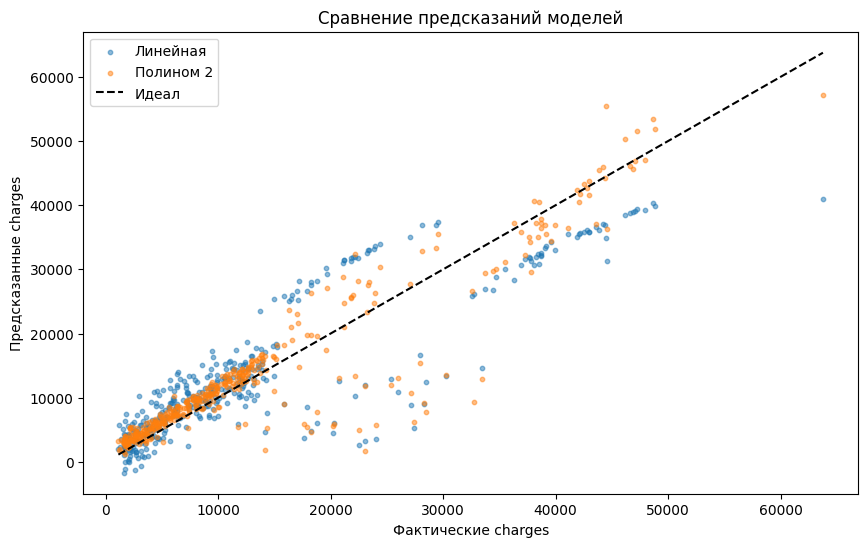

In [15]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_lr, alpha=0.5, label='Линейная', s=10)
plt.scatter(y_test, y_pred_poly2, alpha=0.5, label='Полином 2', s=10)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'k--', label='Идеал')
plt.xlabel('Фактические charges')
plt.ylabel('Предсказанные charges')
plt.legend()
plt.title('Сравнение предсказаний моделей')
plt.show()

## Выводы

1. **Линейная регрессия** — базовое качество (R² ~ 0.78).
2. **Полином 2-й степени** — небольшое улучшение.
3. **Полином 3-й степени** — риск переобучения.

Наилучшая модель — **полином 2-й степени** или **линейная** (по метрикам).

**Бизнес-интерпретация:** медицинские расходы сильнее всего зависят от курения (smoker), возраста (age) и индекса массы тела (bmi).